STAGE 1

In [7]:
import pandas as pd
import numpy as np

# Load the dataset using sep='\t' to specify tab-separated values and header=None since the dataset does not have a header row. 
df = pd.read_csv('SMSSpamCollection', sep='\t', header=None, names=['label', 'message'])

# Display the first 5 rows 
df.head()

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [8]:
# used basic functions to explore the dataset and check for missing values, duplicates, and the distribution of the target variable.
print("1. Dataset Shape (Rows, Columns):", df.shape)

print("2. Missing Values per Column:\n", df.isnull().sum())

print("3. Total Duplicate Rows:", df.duplicated().sum())

print("4. Target Variable Distribution (Counts):\n", df['label'].value_counts())

print("5. Target Variable Distribution (Percentages %):\n", (df['label'].value_counts(normalize=True) * 100).round(2))

print("6. Dataset Info:")
df.info()

1. Dataset Shape (Rows, Columns): (5572, 2)
2. Missing Values per Column:
 label      0
message    0
dtype: int64
3. Total Duplicate Rows: 403
4. Target Variable Distribution (Counts):
 label
ham     4825
spam     747
Name: count, dtype: int64
5. Target Variable Distribution (Percentages %):
 label
ham     86.59
spam    13.41
Name: proportion, dtype: float64
6. Dataset Info:
<class 'pandas.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   label    5572 non-null   str  
 1   message  5572 non-null   str  
dtypes: str(2)
memory usage: 87.2 KB


1.1 Dataset Understanding and Description:
-First loaded the data useing pd.read_csv in pandas using the parameter because the dataset is not speatead with comma 
- The SMS Spam Collection dataset has two attributes and 5,572 messages.  
- There is no missing data in the dataset. There are 403 duplicate rows.  
- `label` (Target Variable): A categorical variable with two classes that indicate the legitimacy of the message. `ham`: 4,825 legitimate messages, and `spam`: 747 unsolicited messages.  
- `message` (Feature): An unstructured text attribute containing the raw SMS content.  
- The dataset has a significant class imbalance in the labels, with 4,825 (86.59%) messages classified as ham and 747 (13.41%) classified as spam.

In [9]:
#Remove duplicate rows and reset index
df_clean = df.drop_duplicates(keep='first').reset_index(drop=True)

# Check for inconsistent whitespace-only messages
df_clean['message'] = df_clean['message'].str.strip()
# to check for empty messages after stripping whitespace
empty_msgs = (df_clean['message'] == '').sum()

df_clean['char_length'] = df_clean['message'].apply(len)
df_clean['word_count'] = df_clean['message'].apply(lambda x: len(x.split()))

print("1. Shape After Removing Duplicates:", df_clean.shape)
print("2. Empty Messages Found:", empty_msgs)
print("3. Target Distribution After Cleaning:\n", df_clean['label'].value_counts())
print("4. Target Percentages After Cleaning (%):\n", (df_clean['label'].value_counts(normalize=True) * 100).round(2))
print("5. Summary Statistics for Message :\n", df_clean[['char_length', 'word_count']].describe().round(2))

1. Shape After Removing Duplicates: (5169, 4)
2. Empty Messages Found: 0
3. Target Distribution After Cleaning:
 label
ham     4516
spam     653
Name: count, dtype: int64
4. Target Percentages After Cleaning (%):
 label
ham     87.37
spam    12.63
Name: proportion, dtype: float64
5. Summary Statistics for Message :
        char_length  word_count
count      5169.00     5169.00
mean         79.31       15.44
std          58.43       11.12
min           2.00        1.00
25%          36.00        7.00
50%          61.00       12.00
75%         118.00       22.00
max         910.00      171.00


1.2 Handling Missing Values, Duplicates, Inconsistent Data, and Outliers:
there are no null values or empty white spaces, stripped text is used to ensure data consistency 

403 duplicate records were removed using drop_duplicates, reducing the dataset from 5,572 to 5,169 unique messages, the dataset contains 4,516 ham messages which about (87.37%) and 653 spam messages (12.63%).
Why: The importance of removing duplicate data to prevent data leakage in the training, validation and test set that will affect the accuracy because the model will memorize the repeated spam.

Creating new cols char_length and word_count to extract structural meta data from the message column , so the model be able to identify pattern in the message length to identify when it spam or ham 
 Why: In SMS text classification, extreme lengths represent genuine user behavior, for example short replies like "Ok" vs. lengthy promotional texts. rather than data corruption. So, these records were retained to preserve real-world variance, and their numerical scale differences will be mitigated via feature scaling.   



In [10]:
import string
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

# 1. Target Encoding to turn  ham -> 0, spam -> 1
df_clean['label_encoded'] = df_clean['label'].map({'ham': 0, 'spam': 1})

# 2. Feature Engineering: Extract domain-specific numerical features
df_clean['digit_count'] = df_clean['message'].apply(lambda x: sum(c.isdigit() for c in x))
df_clean['uppercase_count'] = df_clean['message'].apply(lambda x: sum(c.isupper() for c in x))
df_clean['special_char_count'] = df_clean['message'].apply(lambda x: sum(c in string.punctuation or c in '£€$' for c in x))

# 3. Text Preprocessing (Lowercase, remove punctuation/numbers, remove stopwords)
def preprocess_text(text):
    text = text.lower()
    text = ''.join([c for c in text if c not in string.punctuation and not c.isdigit() and c not in '£€$'])
    words = [word for word in text.split() if word not in ENGLISH_STOP_WORDS]
    return ' '.join(words)

df_clean['clean_message'] = df_clean['message'].apply(preprocess_text)

# Compare mean values of engineered features between Ham (0) and Spam (1)
print("Mean Feature Values by Class (0 = Ham, 1 = Spam):")
display(df_clean.groupby('label')[['char_length', 'word_count', 'digit_count', 'uppercase_count', 'special_char_count']].mean().round(2))

# Display first 5 rows with new engineered columns
df_clean[['label', 'label_encoded', 'char_length', 'digit_count', 'uppercase_count', 'clean_message']].head()

Mean Feature Values by Class (0 = Ham, 1 = Spam):


,char_length,word_count,digit_count,uppercase_count,special_char_count
label,,,,,
ham,70.87,14.24,0.30,3.98,3.83
spam,137.66,23.74,15.49,15.27,6.05


,label,label_encoded,char_length,digit_count,uppercase_count,clean_message
0,ham,0,111,0,3,jurong point crazy available bugis n great wor...
1,ham,0,29,0,2,ok lar joking wif u oni
2,spam,1,155,25,10,free entry wkly comp win fa cup final tkts st ...
3,ham,0,49,0,2,u dun say early hor u c say
4,ham,0,61,0,2,nah dont think goes usf lives


1.3 Encoding, Text Preprocessing, and Feature Engineering:
Target Encoding: The categorical target variable label it was  binary-encoded into label_encoded (ham -->0, spam -->1) to make it compatible with mathematical optimization in machine-learning classifiers and neural networks. 
   
Domain-Specific Feature Engineering: Five structural meta-features were engineered from the raw text prior to cleaning: char_length, word_count, digit_count, uppercase_count, and special_char_count. 
why: Group-level mean analysis revealed drastic behavioral differences between classes , spam messages average 15.49 digits, 15.27 uppercase letters, and 137.66 characters, compared to just 0.30 digits, 3.98 uppercase letters, and 70.87 characters in ham messages. Preserving these structural indicators before stripping punctuation and numbers ensures critical discriminative signals are not lost. 

In text Preprocessing,To prepare the unstructured text for TF-IDF vectorization, a clean_message attribute was generated by converting characters to lowercase, removing punctuation, currency symbols, and digits, and filtering out standard English stopwords.
why: This reduces vocabulary noise and dimensionality while retaining core semantic tokens




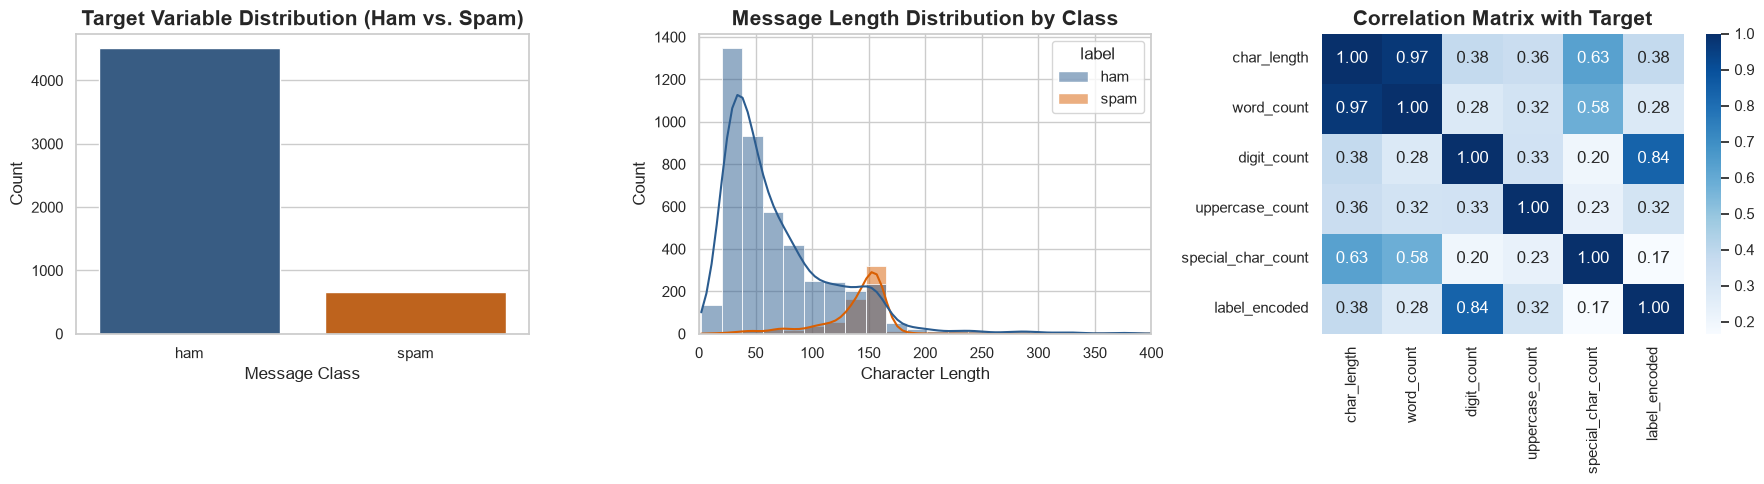

Feature Relevance (Correlation with Target 'label_encoded'):
digit_count           0.8369
char_length           0.3798
uppercase_count       0.3184
word_count            0.2839
special_char_count    0.1661
Name: label_encoded, dtype: float64


In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

# This step for style setup
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1 Target Class Distribution
sns.countplot(data=df_clean, x='label', hue='label', palette=['#2b5c8f', '#d95f02'], legend=False, ax=axes[0])
axes[0].set_title('Target Variable Distribution (Ham vs. Spam)', fontsize=15, fontweight='bold')
axes[0].set_xlabel('Message Class')
axes[0].set_ylabel('Count')

# Plot 2: Character Length Distribution by Class
sns.histplot(data=df_clean, x='char_length', hue='label', bins=50, kde=True, palette=['#2b5c8f', '#d95f02'], ax=axes[1])
axes[1].set_title('Message Length Distribution by Class', fontsize=15, fontweight='bold')
axes[1].set_xlabel('Character Length')
axes[1].set_xlim(0, 400)

# Plot 3: Correlation Heatmap of Engineered Features with Target
engineered_cols = ['char_length', 'word_count', 'digit_count', 'uppercase_count', 'special_char_count', 'label_encoded']
corr_matrix = df_clean[engineered_cols].corr()
sns.heatmap(corr_matrix, annot=True, cmap='Blues', fmt='.2f', ax=axes[2])
axes[2].set_title('Correlation Matrix with Target', fontsize=15, fontweight='bold')

plt.tight_layout()
plt.show()

# Print exact correlation ranking with target variable
print("Feature Relevance (Correlation with Target 'label_encoded'):")
print(corr_matrix['label_encoded'].drop('label_encoded').sort_values(ascending=False).round(4))

1.4 Exploratory Data Analysis (EDA) and Feature Relevance: Target Distribution Analysis:
 Visualizing the target variable confirms a severe class imbalance (87.37% ham vs. 12.63% spam). Accuracy alone is not enough for model evaluation; stratified data splitting and metrics such as Precision, Recall, F1-score, and ROC-AUC will be prioritized in later stages. 
 Behavioral Length Patterns: The character length distribution reveals a bimodal separation between classes. Legitimate ham messages follow a right-skewed distribution concentrated between 20 and 80 characters, whereas spam messages cluster sharply near 140–160 characters (the standard single-SMS character limit used by marketers to maximize promotional content).   
To identifying the Most Relevant Features: Pearson correlation analysis against label_encoded ranks the engineered features in the following order of predictive relevance: 
digit_count (r = 0.8369): The strongest structural predictor of spam, reflecting phone numbers, prize claims, and text-back shortcodes.
char_length (r = 0.3798): Moderate positive correlation means that longer messages are more likely to be spam.
uppercase_count (r = 0.3184): Captures aggressive promotional capitalization.
word_count (r = 0.2839) and special_char_count (r = 0.1661).
therefore, there is  a high collinearity of r = 0.97 between char_length and word_count).   



STAGE 2


In [12]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from scipy.sparse import hstack

# Define features (X) and target (y)
num_cols = ['char_length', 'word_count', 'digit_count', 'uppercase_count', 'special_char_count']
X = df_clean[['clean_message'] + num_cols]
y = df_clean['label_encoded']

# Step 1: Split into 70% Training and 30% Temporary (Validation + Test) using Stratified Sampling
X_train_raw, X_temp_raw, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

# Step 2: Split the 30% Temporary set equally into 15% Validation and 15% Test
X_val_raw, X_test_raw, y_val, y_test = train_test_split(
    X_temp_raw, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

# Step 3: Apply TF-IDF Vectorization on text (Fit ONLY on Training set to prevent data leakage)
tfidf = TfidfVectorizer(max_features=3000)
X_train_tfidf = tfidf.fit_transform(X_train_raw['clean_message'])
X_val_tfidf = tfidf.transform(X_val_raw['clean_message'])
X_test_tfidf = tfidf.transform(X_test_raw['clean_message'])

# Step 4: Apply StandardScaler on numerical engineered features (Fit ONLY on Training set)
scaler = StandardScaler()
X_train_num = scaler.fit_transform(X_train_raw[num_cols])
X_val_num = scaler.transform(X_val_raw[num_cols])
X_test_num = scaler.transform(X_test_raw[num_cols])

# Step 5: Combine TF-IDF features and Scaled numerical features into final matrices
X_train = hstack([X_train_tfidf, X_train_num]).tocsr()
X_val = hstack([X_val_tfidf, X_val_num]).tocsr()
X_test = hstack([X_test_tfidf, X_test_num]).tocsr()

# Print summary of splits to verify shapes and stratification
print(f"Training Set   (70%): {X_train.shape[0]} samples | Spam Ratio: {(y_train.mean()*100):.2f}% | Matrix Shape: {X_train.shape}")
print(f"Validation Set (15%): {X_val.shape[0]} samples  | Spam Ratio: {(y_val.mean()*100):.2f}% | Matrix Shape: {X_val.shape}")
print(f"Test Set       (15%): {X_test.shape[0]} samples  | Spam Ratio: {(y_test.mean()*100):.2f}% | Matrix Shape: {X_test.shape}")

Training Set   (70%): 3618 samples | Spam Ratio: 12.63% | Matrix Shape: (3618, 3005)
Validation Set (15%): 775 samples  | Spam Ratio: 12.65% | Matrix Shape: (775, 3005)
Test Set       (15%): 776 samples  | Spam Ratio: 12.63% | Matrix Shape: (776, 3005)


2. Feature Vectorization and Scaling (Preventing Data Leakage):
The cleaned dataset contained 5,169 records. It was divided into training, validation and test sets using a stratified 70% / 15% / 15% split with random_state=42.

Training Set (70%)
•	Records: 3,618
•	Spam Proportion: 12.63%
•	Purpose: Train the models.
Validation Set (15%)
•	Records: 775
•	Spam Proportion: 12.65%
•	Purpose: Tune hyperparameters and check for underfitting or overfitting.
Test Set (15%)
•	Records: 776
•	Spam Proportion: 12.63%
•	Purpose: Evaluate and compare the final models on unseen data.


This split kept most records for training while leaving separate sets for tuning and final evaluation. Stratification maintained approximately the same spam proportion across all three sets. The validation and test sets each contained about 98 spam messages.
After splitting the data, the text vectorizer and numerical scaler were fitted only on the training set using fit_transform. They were then applied to the validation and test sets using transform. This kept information from the evaluation sets out of preprocessing decisions.
The clean_message column was converted into numerical features using TfidfVectorizer(max_features=3000). TF-IDF gives less weight to words that appear in many messages. Limiting the vocabulary to 3,000 features reduced storage and processing requirements.
The five numerical features—char_length, word_count, digit_count, uppercase_count and special_char_count—were scaled using StandardScaler. The scaler used the training data’s statistics to give each feature a mean of 0 and a standard deviation of 1 on that set. Scaling helps models such as Neural Networks, Logistic Regression and SVMs handle features measured on different scales.
The scaled numerical features were combined with the TF-IDF matrix, producing 3,005 features per record.

